{
  "dataset": {
    "rows": 4424,
    "source_features": 21,
    "missing_values": 0,
    "target_distribution": {
      "Dropout": 1421,
      "Enrolled": 794,
      "Graduate": 2209
    }
  },
  "design": {
    "task": "three-class early student-outcome classification",
    "excluded_features": [
      "Debtor",
      "Tuition fees up to date",
      "Scholarship holder",
      "all first- and second-semester curricular unit fields"
    ],
    "predictor_count": 21,
    "categorical_predictors": [
      "Marital status",
      "Application mode",
      "Application order",
      "Course",
      "Daytime/evening attendance",
      "Previous qualification",
      "Nacionality",
      "Mother's qualification",
      "Father's qualification",
      "Mother's occupation",
      "Father's occupation",
      "Displaced",
      "Educational special needs",
      "Gender",
      "International"
    ],
    "numeric_predictors": [
      "Previous qualification (grade)",
      "Admission grade"

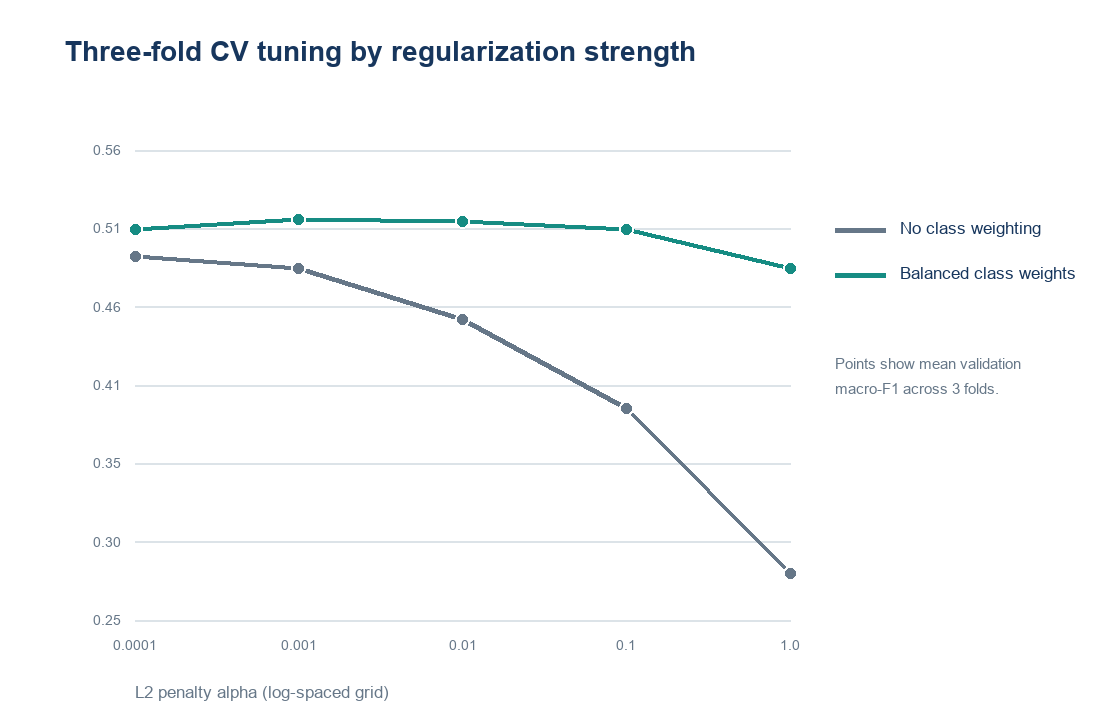

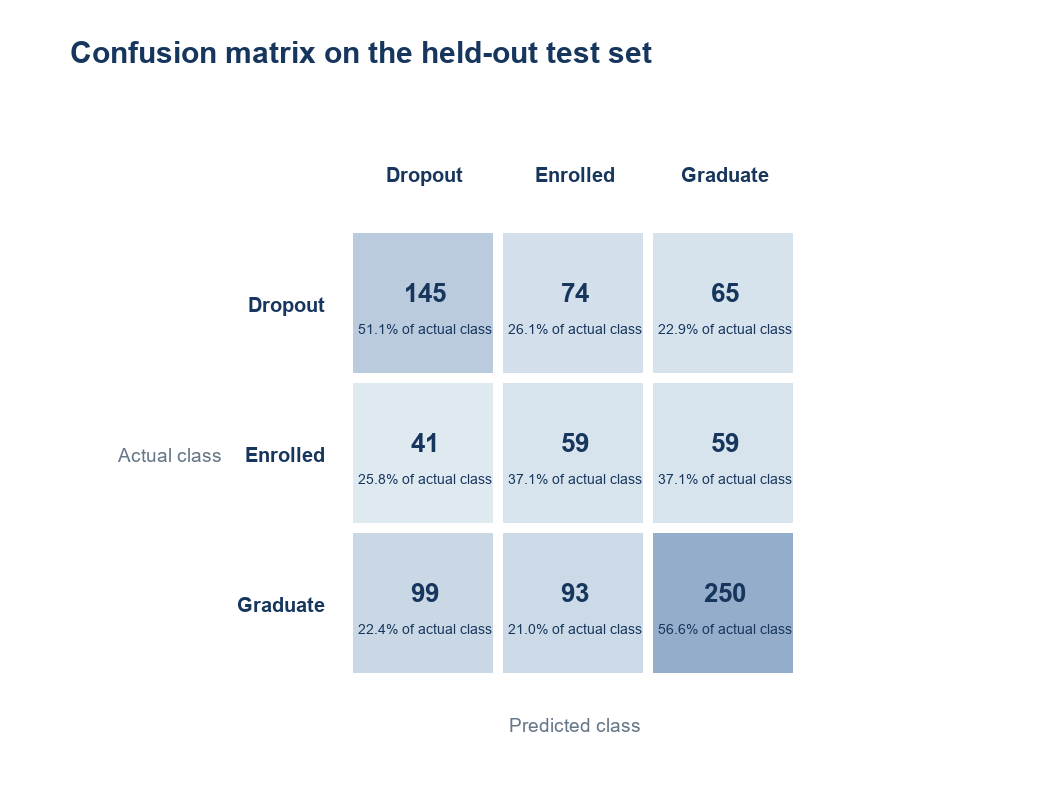

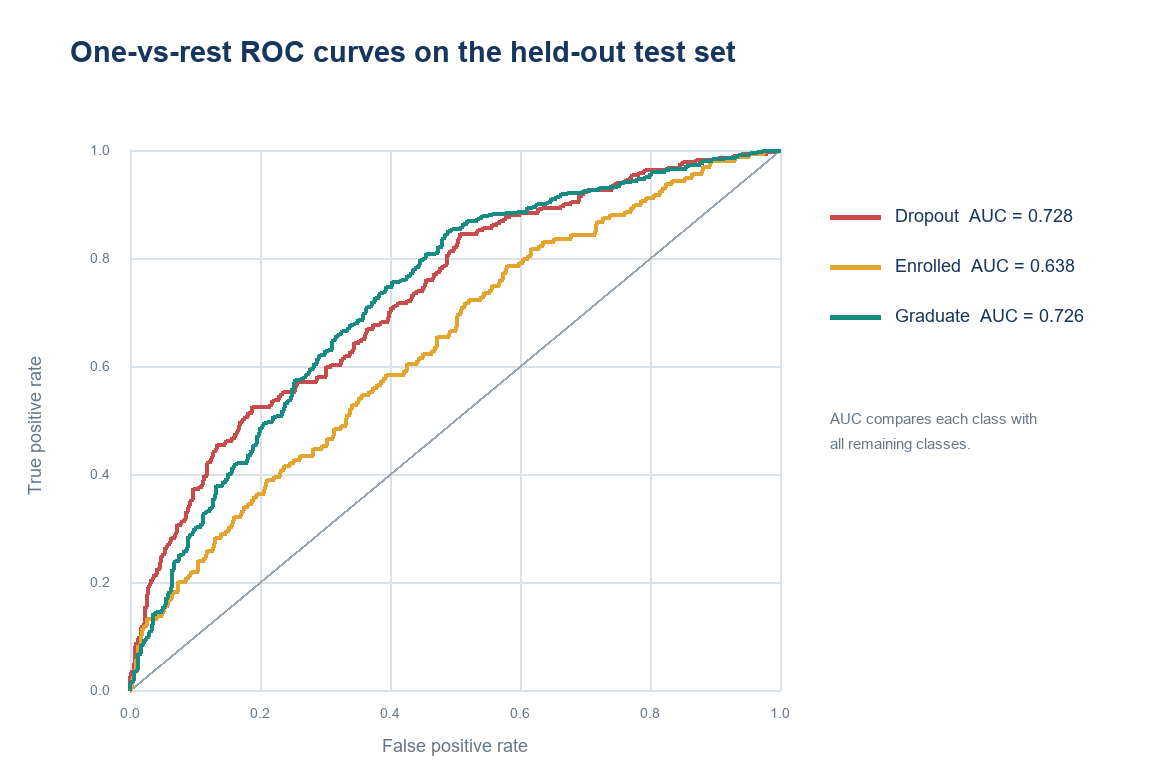

In [1]:
"""Week 5: early student-outcome classification using NumPy and pandas.
The notebook cell below this module runs the full analysis in one block.
"""
from pathlib import Path
from math import exp, log
import json
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFont

TARGET='Target'
CLASSES=['Dropout','Enrolled','Graduate']
NUMERIC=['Previous qualification (grade)','Admission grade','Age at enrollment','Unemployment rate','Inflation rate','GDP']
CATEGORICAL=['Marital status','Application mode','Application order','Course','Daytime/evening attendance','Previous qualification','Nacionality',"Mother's qualification","Father's qualification","Mother's occupation","Father's occupation",'Displaced','Educational special needs','Gender','International']
EXCLUDED=['Debtor','Tuition fees up to date','Scholarship holder']
COLORS={'Dropout':'#C94C4C','Enrolled':'#E3A52F','Graduate':'#168C83'}
NAVY='#17365D'; GRID='#DCE3E8'; GRAY='#667788'

def softmax(z):
    z=z-np.max(z,axis=1,keepdims=True)
    e=np.exp(np.clip(z,-50,50))
    return e/e.sum(axis=1,keepdims=True)

def stratified_holdout(y,test_fraction=0.20,seed=42):
    rng=np.random.default_rng(seed); train=[]; test=[]
    for c in range(len(CLASSES)):
        idx=np.flatnonzero(y==c); rng.shuffle(idx)
        ntest=max(1,int(round(len(idx)*test_fraction)))
        test.extend(idx[:ntest]); train.extend(idx[ntest:])
    return np.array(sorted(train)),np.array(sorted(test))

def stratified_folds(y,k=3,seed=2025):
    rng=np.random.default_rng(seed); buckets=[[] for _ in range(k)]
    for c in range(len(CLASSES)):
        idx=np.flatnonzero(y==c); rng.shuffle(idx)
        for j,part in enumerate(np.array_split(idx,k)): buckets[j].extend(part.tolist())
    return [np.array(sorted(b),dtype=int) for b in buckets]

def fit_transform(train,test):
    """Fit preprocessing on training rows only; apply it to train and validation/test."""
    chunks_train=[]; chunks_test=[]; state={}
    for col in NUMERIC:
        a=pd.to_numeric(train[col],errors='coerce').to_numpy(dtype=float)
        b=pd.to_numeric(test[col],errors='coerce').to_numpy(dtype=float)
        med=float(np.nanmedian(a)); a=np.where(np.isfinite(a),a,med); b=np.where(np.isfinite(b),b,med)
        mean=float(a.mean()); sd=float(a.std(ddof=0)); sd=sd if sd>1e-12 else 1.0
        chunks_train.append(((a-mean)/sd)[:,None]); chunks_test.append(((b-mean)/sd)[:,None])
        state[col]={'median':med,'mean':mean,'sd':sd}
    for col in CATEGORICAL:
        a=train[col].fillna('__MISSING__').astype(str).to_numpy()
        b=test[col].fillna('__MISSING__').astype(str).to_numpy()
        levels=sorted(set(a.tolist()))
        # Use one category as reference; unseen validation/test levels map to all-zero.
        for level in levels[1:]:
            chunks_train.append((a==level).astype(float)[:,None])
            chunks_test.append((b==level).astype(float)[:,None])
        state[col]={'levels':levels}
    Xtr=np.concatenate(chunks_train,axis=1); Xte=np.concatenate(chunks_test,axis=1)
    return Xtr,Xte,state

class SoftmaxRegression:
    """Multinomial logistic regression trained with L2-regularized batch gradient descent."""
    def __init__(self,alpha=0.01,class_weight='none',max_iter=1200,learning_rate=0.03,tolerance=1e-6):
        self.alpha=alpha; self.class_weight=class_weight; self.max_iter=max_iter; self.learning_rate=learning_rate; self.tolerance=tolerance
    def fit(self,X,y):
        m,p=X.shape; xb=np.column_stack([np.ones(m),X]); yoh=np.eye(len(CLASSES))[y]
        self.W=np.zeros((p+1,len(CLASSES))); first=np.zeros_like(self.W); second=np.zeros_like(self.W)
        if self.class_weight=='balanced':
            freq=np.bincount(y,minlength=len(CLASSES)); class_weights=m/(len(CLASSES)*freq)
            sample_weights=class_weights[y]
        else: sample_weights=np.ones(m)
        for it in range(self.max_iter):
            probs=softmax(xb@self.W)
            grad=xb.T@((probs-yoh)*sample_weights[:,None])/sample_weights.sum()
            grad[1:]+=self.alpha*self.W[1:]
            first=0.9*first+0.1*grad; second=0.999*second+0.001*(grad*grad)
            first_hat=first/(1-0.9**(it+1)); second_hat=second/(1-0.999**(it+1))
            self.W-=self.learning_rate*first_hat/(np.sqrt(second_hat)+1e-8)
            if np.linalg.norm(grad)<self.tolerance: break
        self.n_iter_=it+1; self.converged_=bool(np.linalg.norm(grad)<self.tolerance)
        return self
    def predict_proba(self,X):
        return softmax(np.column_stack([np.ones(len(X)),X])@self.W)
    def predict(self,X):
        return self.predict_proba(X).argmax(axis=1)

def classification_metrics(y_true,y_pred):
    k=len(CLASSES); cm=np.zeros((k,k),dtype=int)
    for a,b in zip(y_true,y_pred): cm[a,b]+=1
    per={}; f1s=[]
    for i,c in enumerate(CLASSES):
        tp=cm[i,i]; fp=cm[:,i].sum()-tp; fn=cm[i,:].sum()-tp
        precision=tp/(tp+fp) if tp+fp else 0.0
        recall=tp/(tp+fn) if tp+fn else 0.0
        f1=2*precision*recall/(precision+recall) if precision+recall else 0.0
        per[c]={'precision':precision,'recall':recall,'f1':f1,'support':int(cm[i,:].sum())}; f1s.append(f1)
    return {'accuracy':float(np.mean(y_true==y_pred)),'macro_precision':float(np.mean([v['precision'] for v in per.values()])),
            'macro_recall':float(np.mean([v['recall'] for v in per.values()])), 'macro_f1':float(np.mean(f1s)),
            'per_class':per,'confusion_matrix':cm.tolist()}

def stratified_cv(Xdf,y,alphas,class_weights,k=3):
    folds=stratified_folds(y,k); scores={}
    for alpha in alphas:
        for cw in class_weights:
            key=f'{alpha}|{cw}'; fold_scores=[]
            for val in folds:
                mask=np.ones(len(y),dtype=bool); mask[val]=False; tr=np.flatnonzero(mask)
                Xtr,Xv,_=fit_transform(Xdf.iloc[tr],Xdf.iloc[val])
                model=SoftmaxRegression(alpha=alpha,class_weight=cw).fit(Xtr,y[tr])
                pred=model.predict(Xv)
                fold_scores.append(classification_metrics(y[val],pred)['macro_f1'])
            scores[key]={'alpha':alpha,'class_weight':cw,'fold_macro_f1':fold_scores,
                         'mean_macro_f1':float(np.mean(fold_scores)),'std_macro_f1':float(np.std(fold_scores,ddof=1))}
    best=max(scores,key=lambda k:scores[k]['mean_macro_f1'])
    return scores[best]['alpha'],scores[best]['class_weight'],scores

def roc_auc_and_curve(y_true,scores,class_idx):
    binary=(y_true==class_idx).astype(int); npos=int(binary.sum()); nneg=len(binary)-npos
    ranks=pd.Series(scores).rank(method='average').to_numpy()
    auc=(ranks[binary==1].sum()-npos*(npos+1)/2)/(npos*nneg)
    order=np.argsort(-scores,kind='mergesort'); s=scores[order]; b=binary[order]
    tp=np.cumsum(b); fp=np.cumsum(1-b)
    ends=np.r_[np.flatnonzero(np.diff(s)),len(s)-1]
    tpr=np.r_[0,tp[ends]/npos,1]; fpr=np.r_[0,fp[ends]/nneg,1]
    return float(auc),fpr,tpr

def make_confusion_plot(cm,path):
    W,H=1050,800; im=Image.new('RGB',(W,H),'white'); d=ImageDraw.Draw(im)
    def ft(sz,b=False):
        try:return ImageFont.truetype(r'C:\Windows\Fonts\arialbd.ttf' if b else r'C:\Windows\Fonts\arial.ttf',sz)
        except:return ImageFont.load_default()
    d.text((70,35),'Confusion matrix on the held-out test set',font=ft(30,True),fill=NAVY)
    cell=150; x0=350; y0=230; vmax=max(1,max(max(row) for row in cm))
    for j,c in enumerate(CLASSES):d.text((x0+j*cell+cell/2,y0-55),c,font=ft(20,True),fill=NAVY,anchor='mm')
    for i,c in enumerate(CLASSES):
        d.text((x0-25,y0+i*cell+cell/2),c,font=ft(20,True),fill=NAVY,anchor='rm')
        total=max(1,sum(cm[i]))
        for j in range(len(CLASSES)):
            val=cm[i][j]; intensity=val/vmax
            rgb=(int(238-90*intensity),int(245-72*intensity),int(248-45*intensity))
            x=x0+j*cell; y=y0+i*cell; d.rectangle((x,y,x+cell-5,y+cell-5),fill=rgb,outline='white',width=3)
            d.text((x+cell/2,y+cell/2-12),str(val),font=ft(26,True),fill=NAVY,anchor='mm')
            d.text((x+cell/2,y+cell/2+24),f'{val/total:.1%} of actual class',font=ft(14),fill=NAVY,anchor='mm')
    d.text((x0+cell*1.5,y0+cell*3+45),'Predicted class',font=ft(19),fill=GRAY,anchor='mm')
    d.text((170,y0+cell*1.5),'Actual class',font=ft(19),fill=GRAY,anchor='mm')
    im.save(path)

def make_roc_plot(curves,path):
    W,H=1150,780; im=Image.new('RGB',(W,H),'white'); d=ImageDraw.Draw(im)
    def ft(sz,b=False):
        try:return ImageFont.truetype(r'C:\Windows\Fonts\arialbd.ttf' if b else r'C:\Windows\Fonts\arial.ttf',sz)
        except:return ImageFont.load_default()
    d.text((70,35),'One-vs-rest ROC curves on the held-out test set',font=ft(29,True),fill=NAVY)
    x0,y0,x1,y1=130,150,780,690
    for q in range(6):
        x=x0+(x1-x0)*q/5; y=y1-(y1-y0)*q/5
        d.line((x,y0,x,y1),fill=GRID,width=2); d.line((x0,y,x1,y),fill=GRID,width=2)
        d.text((x,y1+18),f'{q/5:.1f}',font=ft(14),fill=GRAY,anchor='mt')
        d.text((x0-20,y),f'{q/5:.1f}',font=ft(14),fill=GRAY,anchor='rm')
    d.line((x0,y1,x1,y0),fill='#9AA7B2',width=2)
    for c,color,(auc,fpr,tpr) in zip(CLASSES,[COLORS[x] for x in CLASSES],curves):
        points=[(x0+f*(x1-x0),y1-t*(y1-y0)) for f,t in zip(fpr,tpr)]
        # Cap drawing complexity while preserving the curve's course.
        if len(points)>900: points=[points[int(i)] for i in np.linspace(0,len(points)-1,900)]
        d.line(points,fill=color,width=4)
    d.text((455,745),'False positive rate',font=ft(18),fill=GRAY,anchor='mm')
    label=Image.new('RGBA',(220,38),(255,255,255,0)); ld=ImageDraw.Draw(label); ld.text((110,19),'True positive rate',font=ft(18),fill=GRAY,anchor='mm'); label=label.rotate(90,expand=True); im.paste(label,(15,315),label)
    for j,(c,color,(auc,_,_)) in enumerate(zip(CLASSES,[COLORS[x] for x in CLASSES],curves)):
        y=205+j*50; d.line((830,y+12,880,y+12),fill=color,width=5); d.text((895,y),f'{c}  AUC = {auc:.3f}',font=ft(18),fill=NAVY)
    d.text((830,410),'AUC compares each class with',font=ft(15),fill=GRAY); d.text((830,435),'all remaining classes.',font=ft(15),fill=GRAY)
    im.save(path)

def make_tuning_plot(cv_results,alphas,path):
    W,H=1100,720; im=Image.new('RGB',(W,H),'white'); d=ImageDraw.Draw(im)
    def ft(sz,b=False):
        try:return ImageFont.truetype(r'C:\Windows\Fonts\arialbd.ttf' if b else r'C:\Windows\Fonts\arial.ttf',sz)
        except:return ImageFont.load_default()
    d.text((65,35),'Three-fold CV tuning by regularization strength',font=ft(28,True),fill=NAVY)
    x0,y0,x1,y1=135,150,790,620; ymin,ymax=0.25,0.56
    for i in range(7):
        y=y1-(y1-y0)*i/6; val=ymin+(ymax-ymin)*i/6
        d.line((x0,y,x1,y),fill=GRID,width=2); d.text((x0-14,y),f'{val:.2f}',font=ft(14),fill=GRAY,anchor='rm')
    labels=[str(a) for a in alphas]; xs=[x0+(x1-x0)*i/(len(alphas)-1) for i in range(len(alphas))]
    for x,label in zip(xs,labels): d.text((x,y1+20),label,font=ft(14),fill=GRAY,anchor='mt')
    d.text((x0,y1+62),'L2 penalty alpha (log-spaced grid)',font=ft(17),fill=GRAY)
    for cw,color in [('none',GRAY),('balanced',COLORS['Graduate'])]:
        vals=[cv_results[f'{a}|{cw}']['mean_macro_f1'] for a in alphas]
        pts=[]
        for x,v in zip(xs,vals):
            y=y1-(v-ymin)/(ymax-ymin)*(y1-y0); pts.append((x,y))
        d.line(pts,fill=color,width=5)
        for x,y in pts:d.ellipse((x-7,y-7,x+7,y+7),fill=color,outline='white',width=2)
    d.line((835,230,885,230),fill=GRAY,width=5); d.text((900,218),'No class weighting',font=ft(17),fill=NAVY)
    d.line((835,275,885,275),fill=COLORS['Graduate'],width=5); d.text((900,263),'Balanced class weights',font=ft(17),fill=NAVY)
    d.text((835,355),'Points show mean validation',font=ft(15),fill=GRAY); d.text((835,380),'macro-F1 across 3 folds.',font=ft(15),fill=GRAY)
    im.save(path)

def run_analysis(csv_path,output_dir='.'):
    out=Path(output_dir); out.mkdir(parents=True,exist_ok=True)
    df=pd.read_csv(csv_path,sep=';'); df.columns=[c.strip().replace('\t','') for c in df.columns]
    df[TARGET]=df[TARGET].astype(str).str.strip()
    missing=[c for c in NUMERIC+CATEGORICAL+[TARGET] if c not in df.columns]
    if missing: raise ValueError(f'Missing required columns: {missing}')
    unexpected=set(df[TARGET].unique())-set(CLASSES)
    if unexpected: raise ValueError(f'Unexpected target labels: {unexpected}')
    features=df[NUMERIC+CATEGORICAL].copy(); y=np.array([CLASSES.index(v) for v in df[TARGET]])
    train_idx,test_idx=stratified_holdout(y)
    X_train=features.iloc[train_idx].reset_index(drop=True); y_train=y[train_idx]
    X_test=features.iloc[test_idx].reset_index(drop=True); y_test=y[test_idx]
    # Grid search uses only the training partition and fold-specific preprocessing.
    alphas=[0.0001,0.001,0.01,0.1,1.0]
    class_weights=['none','balanced']
    best_alpha,best_class_weight,cv_results=stratified_cv(X_train,y_train,alphas,class_weights,k=3)
    Xtr,Xte,preprocess_state=fit_transform(X_train,X_test)
    model=SoftmaxRegression(alpha=best_alpha,class_weight=best_class_weight).fit(Xtr,y_train)
    prob=model.predict_proba(Xte); pred=prob.argmax(axis=1)
    metrics=classification_metrics(y_test,pred)
    curves=[]; aucs={}
    for i,c in enumerate(CLASSES):
        auc,fpr,tpr=roc_auc_and_curve(y_test,prob[:,i],i); aucs[c]=auc; curves.append((auc,fpr,tpr))
    majority=int(np.bincount(y_train,minlength=len(CLASSES)).argmax())
    base_metrics=classification_metrics(y_test,np.full(len(y_test),majority))
    baseline={'accuracy':base_metrics['accuracy'],'macro_f1':base_metrics['macro_f1'],'predicts_class':CLASSES[majority]}
    # Store figures and numerical metrics for the notebook and report.
    cm_path=out/'week5_confusion_matrix.png'; roc_path=out/'week5_roc_curves.png'; tuning_path=out/'week5_tuning.png'
    make_confusion_plot(metrics['confusion_matrix'],cm_path); make_roc_plot(curves,roc_path); make_tuning_plot(cv_results,alphas,tuning_path)
    results={'dataset':{'rows':len(df),'source_features':len(NUMERIC)+len(CATEGORICAL),'missing_values':int(df[NUMERIC+CATEGORICAL+[TARGET]].isna().sum().sum()),
                        'target_distribution':df[TARGET].value_counts().reindex(CLASSES).to_dict()},
      'design':{'task':'three-class early student-outcome classification','excluded_features':EXCLUDED+['all first- and second-semester curricular unit fields'],
        'predictor_count':len(NUMERIC)+len(CATEGORICAL),'categorical_predictors':CATEGORICAL,'numeric_predictors':NUMERIC,
        'split':'stratified 80/20 holdout; random seed 42','cv':'3-fold stratified CV on training data only; macro-F1 selection',
        'algorithm':'multinomial softmax logistic regression with L2 penalty; NumPy full-batch Adam optimizer','class_weight':best_class_weight,'max_iterations':model.max_iter,'iterations_run':model.n_iter_},
      'tuning':{'alpha_grid':alphas,'class_weight_grid':class_weights,'cv_scores':cv_results,'selected_alpha':best_alpha,'selected_class_weight':best_class_weight},
      'test_metrics':metrics,'ovr_auc':aucs,'mean_ovr_auc':float(np.mean(list(aucs.values()))),'majority_baseline':baseline,
      'artifacts':{'confusion_matrix':str(cm_path.resolve()),'roc_curves':str(roc_path.resolve()),'tuning_plot':str(tuning_path.resolve())}}
    printable={k:v for k,v in results.items() if k!='artifacts'}
    print(json.dumps(printable,indent=2))
    return results

# Change CSV_PATH if your copy of the dataset is stored elsewhere.
CSV_PATH = r'C:\Users\KIIT\AppData\Local\Temp\codex-file-preview-21aksf\data.csv'
OUTPUT_DIR = '.'
RESULTS = run_analysis(CSV_PATH, OUTPUT_DIR)

# Display the generated evaluation figures when this cell is run in Jupyter.
try:
    from IPython.display import display, Image as NotebookImage
    for chart in ['week5_tuning.png', 'week5_confusion_matrix.png', 'week5_roc_curves.png']:
        display(NotebookImage(filename=str(Path(OUTPUT_DIR) / chart)))
except ImportError:
    pass
